# Umbrella sampling and WHAM

Original educational notebook. Read the linked course chapters. All synthetic models are labeled; no material property is inferred from a short run.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'scripts/numerics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Extract the complete repository, then open this notebook from its root or notebooks folder.')
sys.path.insert(0, str(ROOT))
np.set_printoptions(precision=5)


## Execute 13 windows
U(x)=4(x²−1)², kBT=1, harmonic bias strength 12. Each chain includes rejected states. The known analytical result makes this a useful estimator check.

WHAM iterations: 256


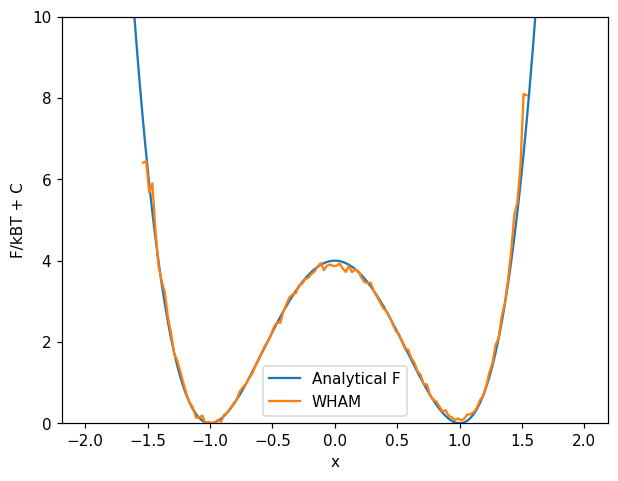

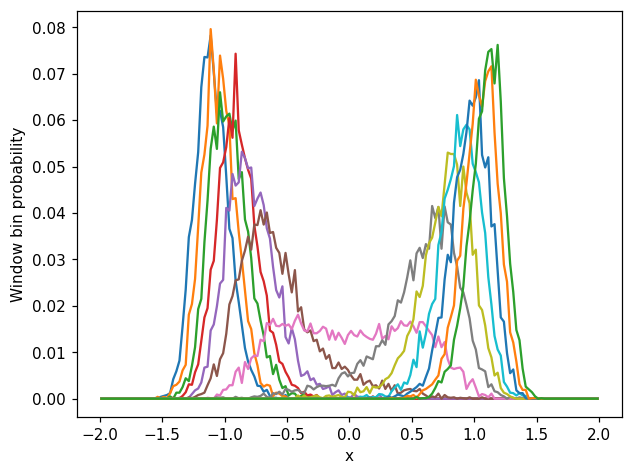

In [2]:
from scripts.free_energy import run
d=run(steps=12000,burn=2000,seed=2026)
plt.plot(d['x'],d['analytical'],label='Analytical F')
plt.plot(d['x'],d['free_energy'],label='WHAM')
plt.ylim(0,10);plt.xlabel('x');plt.ylabel('F/kBT + C');plt.legend();plt.show()
for h in d['histograms']:plt.plot(d['x'],h/h.sum())
plt.xlabel('x');plt.ylabel('Window bin probability');plt.show()
print('WHAM iterations:',int(d['iterations']))

**Exercise:** repeat seeds, double sampling, change bins and remove windows. Numerical convergence of WHAM is not statistical convergence. Estimate uncertainty by resampling independently equilibrated blocks, rerunning the estimator and checking overlap after every resample. The supplied implementation deliberately returns no automatic molecular-rate or confidence claim.